# The 32 screening factors against the seven orthogonal factors

Notebook `04_factor_screening` of the companion repository tests 32 factors one by one. Each one here is the long-short portfolio of the top 30% minus the bottom 30% of the investable universe on its signal, a cross-sectional z-score with the values beyond 2 standard deviations dropped, equally weighted and rebalanced monthly.

Used as test assets, like the industries of Table 7 of the paper, they answer two questions. How much of each factor is just a combination of the seven local factors, and which of them it resembles? And does any of them earn a return the seven factors do not explain?

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from orthofactors.data import (load_brazil_factors, load_brazil_screening, to_monthly, BRAZIL_FACTORS,
                               DATA_START, MONTHLY_SAMPLE)
from orthofactors.decomposition import decompose, variance_levels
from orthofactors.plotting import set_style, SEQUENTIAL

set_style()
Path('results').mkdir(exist_ok = True)

groups = {'Value': ['Book to Price', 'EV to Ebitda', 'Sales to Price', 'Free Cash Flow to Price', 'Earnings Yield', 'Value Composite'],
          'Profitability': ['Return on Equity', 'Return on Assets', 'Gross Profit over Assets', 'Cashflow over Assets', 'Accruals',
                            'Profitability Composite'],
          'Growth': ['Revenue Growth', 'Ebitda Growth', 'Earnings Growth', 'Growth Composite', 'Investments'],
          'Leverage': ['Debt to Assets', 'Debt to Ebitda', 'Debt to Equity', 'Liabilities to Equity', 'Leverage Composite'],
          'Market': ['Momentum', 'Reversal', 'Low Vol', 'Size', 'BAB', 'IVOL'],
          'Magic Formula': ['Return on Capital', 'Earnings Yield MF', 'Debt to Ebit MF', 'Magic Formula Composite']}
group_of = {factor: group for group, members in groups.items() for factor in members}

## Data

Each screening factor starts when its signal has enough history, between January 2010 and March 2011, and before that its return file holds zeros. All 32 start before the sample, so each one covers the 174 months from January 2012 to June 2026, like the seven local factors.

In [2]:
factors = to_monthly(load_brazil_factors()[BRAZIL_FACTORS]).loc[MONTHLY_SAMPLE]

# Before its signal has enough history, a screening factor holds no stocks and its return file holds zeros
first_days = load_brazil_screening(start = DATA_START).ne(0).idxmax()
print(f'Last screening factor to start: {first_days.max():%Y-%m-%d}')
screening = to_monthly(load_brazil_screening()).loc[MONTHLY_SAMPLE]
screening.count().value_counts().sort_index().rename('Factors').rename_axis('Months')

Last screening factor to start: 2011-03-02


Months
174    32
Name: Factors, dtype: int64

## Decomposition

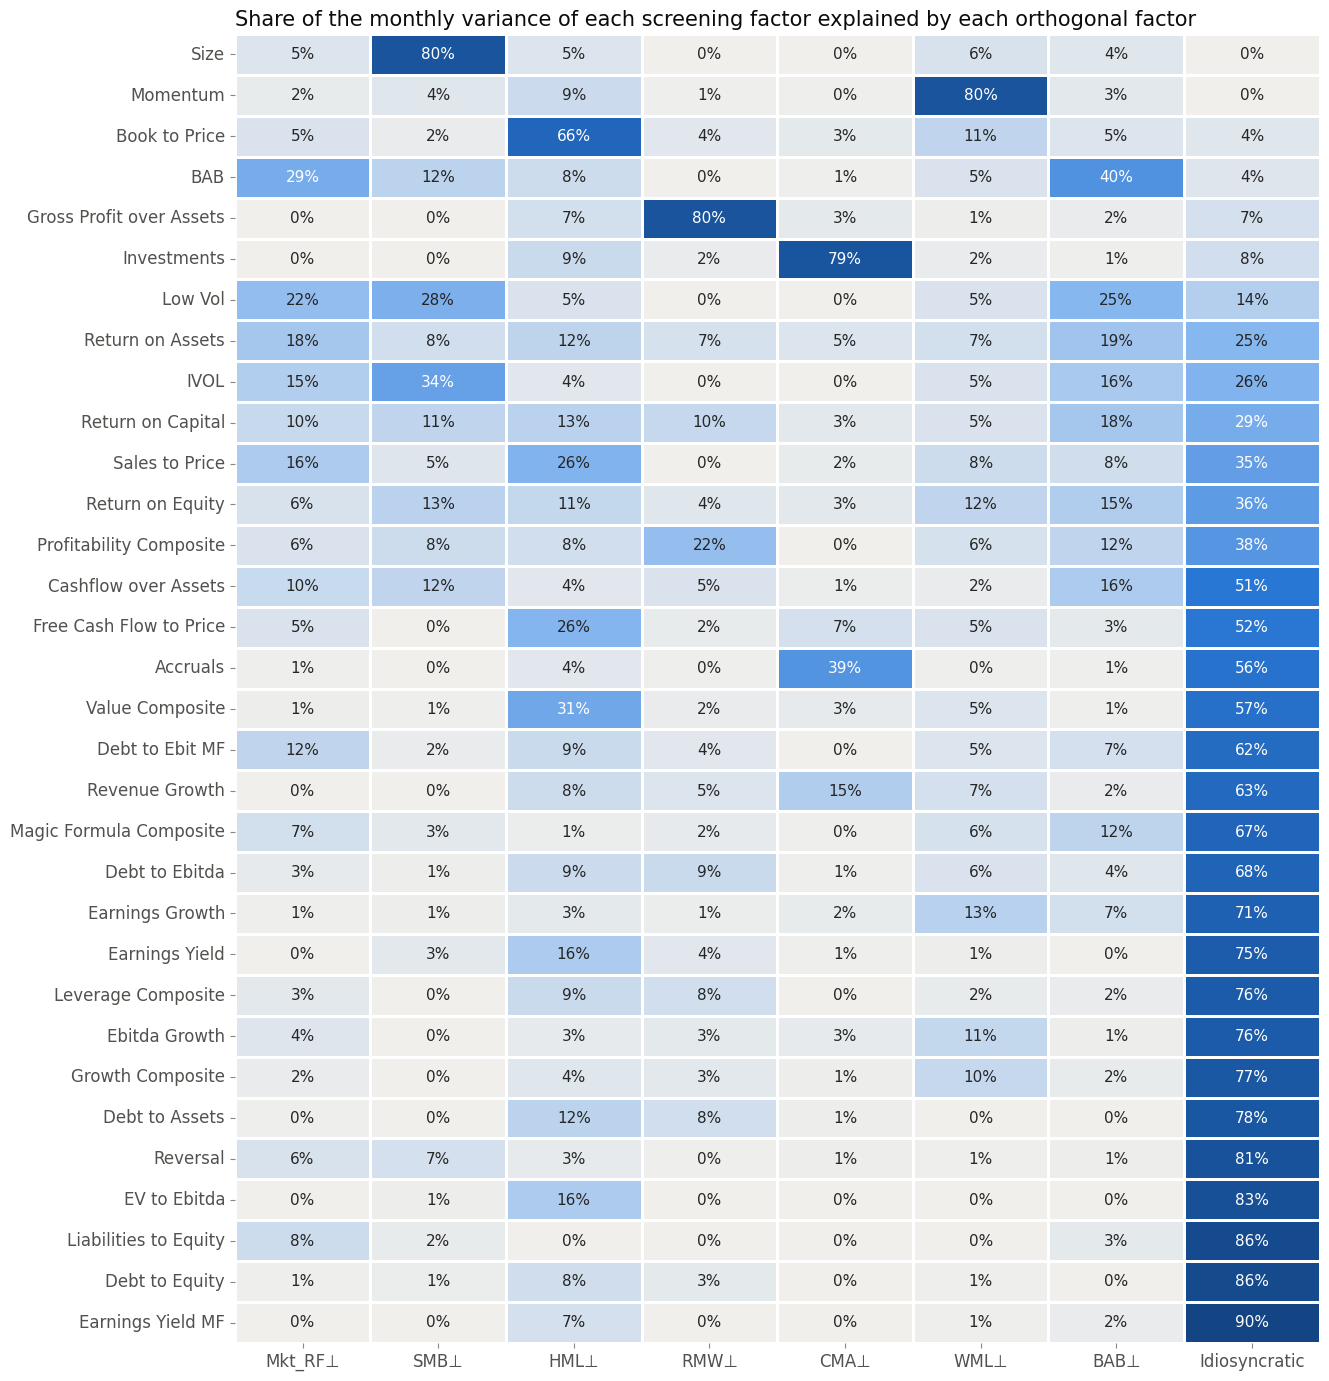

In [3]:
rows = {}
for name in screening.columns:
    result, dr2 = decompose(screening[name], factors, hac_lags = 4)
    rows[name] = pd.concat([dr2, pd.Series({'idiosyncratic': 1 - result.rsquared,
                                            'Alpha': result.params['const'] * 12, 't-statistic': result.tvalues['const'],
                                            'Volatility': screening[name].std() * np.sqrt(12), 'Months': result.nobs})])
table = pd.DataFrame(rows).T
table.insert(0, 'Group', table.index.map(group_of))
components = BRAZIL_FACTORS + ['idiosyncratic']
table = table.sort_values('idiosyncratic')

fig, ax = plt.subplots(figsize = (14, 17))
sns.heatmap(table[components].astype(float), annot = True, fmt = '.0%', cmap = SEQUENTIAL, vmin = 0, vmax = 1, cbar = False,
            linewidths = 2, linecolor = 'white', annot_kws = {'size': 11}, ax = ax)
ax.set_xticklabels([f'{f}⊥' for f in BRAZIL_FACTORS] + ['Idiosyncratic'])
ax.set_ylabel('')
ax.set_title('Share of the monthly variance of each screening factor explained by each orthogonal factor')
ax.grid(False)
plt.show()

The factors are sorted from the most to the least explained.

- **Copies of the local factors.** Size and Momentum are the same portfolios as SMB and WML, so the seven factors explain them fully. Even so, only 80% of their variance goes to their own orthogonal factor: it is the squared resemblance of [`02_brazil_factors`](02_brazil_factors.ipynb), 0.895² = 80% for SMB, because an original factor is a mix of the orthogonal ones. Book to Price, Gross Profit over Assets and Investments are close versions of HML, RMW and CMA built from trimmed z-scores, and the seven factors explain 92% to 96% of them.
- **The dollar-neutral BAB.** The BAB of the screening is the dollar-neutral BAB of the companion. The seven factors explain 96% of it, but only 40% goes to BAB⊥ and 29% to the orthogonal market: that is the market exposure of the dollar-neutral construction.
- **Low risk and profitability.** Low Vol and IVOL split between size (28% and 34%), BAB (25% and 16%) and the market (22% and 15%): the low-volatility stocks are large and low-beta. Return on equity, return on assets, cash flow over assets and the profitability composite also load on BAB⊥ (12% to 19%) and on the market (6% to 18%), since in Brazil the profitable companies have also been the low-beta ones.
- **Accruals load on investment.** CMA⊥ explains 39% of Accruals, in line with the studies that link accruals to the growth of the balance sheet.
- **Leverage, growth and several value ratios are largely new.** At least 78% of the variance of Debt to Assets, Debt to Equity, Liabilities to Equity, EV to Ebitda, Reversal and the Earnings Yield of the Magic Formula is idiosyncratic.

In [4]:
# The screening versions of six of the seven local factors: same signals, but z-scored and trimmed
pairs = {'Size': 'SMB', 'Book to Price': 'HML', 'Gross Profit over Assets': 'RMW', 'Investments': 'CMA', 'Momentum': 'WML', 'BAB': 'BAB'}
pd.DataFrame({name: {'Local factor': local, 'Correlation': screening[name].corr(factors[local]),
                     'Share of its own orthogonal factor': table.loc[name, local], 'R²': 1 - table.loc[name, 'idiosyncratic']}
              for name, local in pairs.items()}).T.style.format({'Correlation': '{:.2f}', 'Share of its own orthogonal factor': '{:.1%}',
                                                                 'R²': '{:.1%}'})

,Local factor,Correlation,Share of its own orthogonal factor,R²
Size,SMB,1.00,80.2%,100.0%
Book to Price,HML,0.98,65.8%,95.9%
Gross Profit over Assets,RMW,0.96,80.1%,93.2%
Investments,CMA,0.96,79.3%,92.4%
Momentum,WML,1.00,80.4%,100.0%
BAB,BAB,0.87,39.5%,95.7%


In [5]:
# The screening factors that are the same daily series as a local factor are left out of the averages,
# of the alphas and of the naive sums below
duplicates = [name for name, local in pairs.items() if (load_brazil_screening()[name] - load_brazil_factors()[local]).abs().max() == 0]
tested = table.drop(duplicates)
print('Identical to a local factor:', duplicates)

# Average shares by group of factors
tested.groupby('Group')[components].mean().loc[list(groups)].style.format('{:.1%}')

Identical to a local factor: ['Size', 'Momentum']


,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
Group,,,,,,,,
Value,4.6%,1.9%,30.1%,2.0%,2.5%,5.3%,2.8%,50.9%
Profitability,6.7%,6.7%,7.5%,19.7%,8.5%,4.7%,10.6%,35.5%
Growth,1.4%,0.3%,5.3%,2.9%,20.0%,8.6%,2.5%,59.0%
Leverage,3.0%,1.0%,7.7%,5.4%,0.5%,1.7%,1.7%,78.9%
Market,18.0%,20.3%,5.0%,0.1%,0.5%,4.2%,20.4%,31.6%
Magic Formula,7.2%,4.2%,7.5%,4.2%,1.0%,4.3%,9.6%,62.1%


By group, the seven factors explain about two thirds of the profitability factors, which split mainly between RMW⊥ (20% on average), BAB⊥ (11%), CMA⊥ (9%) and the market (7%), and about two thirds of the market-based factors: low risk, reversal and the dollar-neutral BAB. The value factors load on HML⊥ (30%) but keep half of their variance unexplained, and the growth factors load on CMA⊥ (20%) and keep 59%. The leverage factors are the least explained group, with 79% of their variance idiosyncratic: the local model has no factor for financial leverage.

## Alphas

The intercept of each regression is the return of the screening factor that the seven local factors do not explain, the same with the original and the orthogonal factors. Newey-West t-statistics with 4 lags.

In [6]:
alphas = tested[['Group', 'Alpha', 't-statistic', 'Volatility', 'Months']].sort_values('t-statistic', ascending = False)
alphas.style.format({'Alpha': '{:.2%}', 't-statistic': '{:.2f}', 'Volatility': '{:.2%}', 'Months': '{:.0f}'})

,Group,Alpha,t-statistic,Volatility,Months
Debt to Assets,Leverage,7.03%,2.87,9.88%,174
Book to Price,Value,2.52%,2.54,16.04%,174
Debt to Equity,Leverage,6.40%,2.35,10.08%,174
Return on Capital,Magic Formula,5.74%,2.20,18.88%,174
Accruals,Profitability,4.83%,1.96,11.24%,174
IVOL,Market,5.07%,1.69,19.35%,174
Value Composite,Value,3.93%,1.48,12.01%,174
Debt to Ebit MF,Magic Formula,4.44%,1.45,13.55%,174
Liabilities to Equity,Leverage,3.75%,1.44,9.31%,174
Low Vol,Market,3.44%,1.24,22.83%,174


Four of the 30 factors have a t-statistic above 2: low leverage (Debt to Assets, 7.0% a year with a t-statistic of 2.9, and Debt to Equity, 6.4%), book to price (2.5%) and the return on capital of the Magic Formula (5.7%), and Accruals falls just short (1.96). Reversal has a negative alpha, −7.9% a year with a t-statistic of −2.2. The leverage factors are also the ones the seven factors explain least, which makes low leverage the clearest candidate for a factor missing from the local model. The dollar-neutral BAB has a negative alpha, −2.0% a year with a t-statistic of −1.3: beyond the beta-neutral BAB and the other factors, it adds nothing.

With 30 tests, one or two t-statistics beyond 2 are expected by chance alone, and none passes a Bonferroni correction at 5%, which needs a t-statistic of about 3.1; Debt to Assets comes closest, at 2.9. These are in-sample results before costs.

## The naive sum

As in Table 5 of the paper, the sum of $(\beta_k \sigma_k)^2$ with the original factors against the systematic variance.

In [7]:
ratio = pd.Series({name: (lambda t: t.loc['sum', 'original'] / t.loc['systematic', 'original'])(variance_levels(screening[name], factors))
                   for name in tested.index}).loc[tested.index]
ratio.describe()[['min', '25%', '50%', '75%', 'max']].rename('Naive sum / systematic variance').to_frame().T.round(2)

,min,25%,50%,75%,max
Naive sum / systematic variance,0.35,0.62,0.78,1.09,4.37


The naive sum misses the systematic variance in both directions. The median ratio is 0.78, but it goes from 0.35 to 4.37, so ignoring the correlations between the factors can understate the factor risk of a portfolio by two thirds or overstate it more than fourfold.

In [8]:
table.join(ratio.rename('Naive sum / systematic variance')).round(4).to_csv('results/screening_decomposition.csv')